In [ ]:
from xgboost import XGBClassifier

In [1]:
import pandas as pd
import sys
import os

if "Desktop" in os.getcwd():
    base_path = "/Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification"
else:
    base_path = "/home/sakdag/weakly-supervised-fake-news-classification"

print(base_path)
sys.path.append(base_path)
    
from src.utils.path_utils import get_project_root
from src.preprocessing.consts import Datasets
from src.preprocessing.read_raw_data import read_raw_data
from src.preprocessing.read_raw_data import read_csv

# covid_df: pd.DataFrame = read_raw_data(Datasets.NELA_COVID_2021_DATASET)
# elections_df: pd.DataFrame = read_raw_data(Datasets.NELA_ELECTIONS_DATASET_SAMPLED)

/Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification


In [ ]:
covid_df.head()

In [ ]:
for idx, row in covid_df.sample(n=1000).iterrows():
    print(row.content[:1000])
    print("\n\n\n")
    print("------------------------------")

In [ ]:
for idx, row in covid_df.sample(n=1000).iterrows():
    print(row.title[:1000])
    print("\n\n\n")
    print("------------------------------")

In [ ]:
sampled_df = covid_df.sample(n=1000)

In [ ]:
for idx, row in sampled_df.iterrows():
    print(row.content[:1000])
    print("\n\n\n")
    print("------------------------------")

In [ ]:
for i, row in sampled_df.iterrows():
    val = row["content"].encode("ascii", errors="ignore").decode()
    val =  val.replace(" @ @ @ @ @ @ @", "")
    val =  val.replace(" @ @ @ @ @", "")
    sampled_df.at[i,'content'] = val

In [ ]:
for idx, row in sampled_df.iterrows():
    print(row.content[:1000])
    print("\n\n\n")
    print("------------------------------")

In [2]:

sampled_covid_df: pd.DataFrame = read_raw_data(Datasets.NELA_COVID_2021_DATASET_SAMPLED)

Reading dataset from path: /home/sakdag/weakly-supervised-fake-news-classification/data/raw/nela/nela-covid-2021-sampled.csv
Dataframe size: 666


In [6]:
for idx, row in sampled_covid_df.iterrows():
    if "@ @ @ @ @" in row.content:
        print(row.content)
        print(row.title)
        print(row.label)
        print("\n\n\n")
        print("------------------------------")

MADRID ( AP )  Real Madrid midfielder Luka Modric and defender Marcelo have tested positive for the coronavirus , .
Madrid did not give any details of their condition and didn  t say a close contact .
Modric played the entire game when Madrid beat Atletico Madrid 2-0 an unused substitute .
Madrid  s next game is against Cadiz on Sunday .
@ @ @ @ @ Athletic Bilbao three days later in the last game before the league  s winter @ @
Real Madrid players Modric and Marcelo positive for virus
0




------------------------------
Delta variant accounts for 93 % of U.S. COVID cases The Delta variant now makes up more than 93 % the U.S .
Experts warn the surge will likely get worse in the coming weeks Manuel Bojorquez reports , Florida and Texas are leading the nation in new infections .
@ @ @ @ @ , an adjunct assistant professor of emergency medicine at the University of Maryland School of Lana Zak to break down the day 's headlines .
Delta variant accounts for 93% of U.S. COVID cases
0




----

In [ ]:
sampled_covid_df: pd.DataFrame = read_csv(Datasets.NELA_COVID_2021.injected_path)

In [22]:
print(sampled_elections_df.sample(n=10).head())

                                                     id  \
1797  eveningstandard--2020-01-25--Labour Party sees...   
788   slate--2020-09-28--What Do We Really Know Abou...   
2497  washingtonpost--2020-02-27--Opinion | Biden pu...   
7840  sgtreport--2020-12-01--Independent Probe Claim...   
3221  vox--2020-11-13--Fox News’s election fraud pan...   

                                                  title  \
1797  Labour Party sees membership surge amid leader...   
788     What Do We Really Know About Amy Coney Barrett?   
2497  Opinion | Biden pulls it together just when he...   
7840  Independent Probe Claims FBI Showing Proactive...   
3221  Fox Newss election fraud pandering may be its ...   

                                                content  label  \
1797  The Labour Party has reportedly seen a members...      0   
788   Subscribe to What Next on Apple Podcasts for t...      0   
2497  He did seize the opportunity to level some big...      0   
7840  As Donald Trump refu

In [13]:
print(sampled_elections_df.value_counts())

id                                                                                                                                  title                                                                                                                                                     content                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [17]:
sampled_elections_df.label.value_counts()

0    5095
1    4905
Name: model_xgboost_label, dtype: int64

In [ ]:
def is_string_series(s : pd.Series):
    if isinstance(s.dtype, pd.StringDtype):
        # The series was explicitly created as a string series (Pandas>=1.0.0)
        return True
    elif s.dtype == 'object':
        # Object series, check each value
        return all((v is None) or isinstance(v, str) for v in s)
    else:
        return False

In [ ]:
print(is_string_series(covid_df.content))

In [ ]:
print(len(covid_df))
covid_df.dropna(inplace=True)
print(len(covid_df))

In [ ]:
for idx, row in covid_df.iterrows():
    if not isinstance(row.title, str):
        print(row.title)
        break

In [ ]:
print(covid_df.dtypes)
print(len(covid_df))

In [ ]:
from src.utils.preprocessing_utils import cleanup_df

print(len(covid_df))
covid_cleaned_df = cleanup_df(covid_df)
print(len(covid_cleaned_df))

In [ ]:
covid_cleaned_df['content_length']  = covid_cleaned_df['content'].str.len()

In [ ]:
covid_cleaned_df["content"].apply(len).mean()

In [ ]:
covid_cleaned_df.head()

In [ ]:
index = covid_cleaned_df.content_length.argmax()
covid_cleaned_df.iloc[index]

In [ ]:
covid_df_shorter = covid_cleaned_df[covid_cleaned_df['content'].apply(len) < 5000] 

In [ ]:
len(covid_df_shorter)

In [ ]:
covid_df_shorter.hist(column='content_length', bins=200);

In [ ]:
import en_core_web_sm
nlp = en_core_web_sm.load()

In [18]:
import spacy
nlp = spacy.load("en_core_web_sm")

for idx, row in sampled_elections_df.iterrows():
#     print(row.content)
    doc = nlp(row.content)
#     for token in doc:
#         print(token.pos_)
#         print(token)
#         print(type(token))
#     words_lower = [word.text.lower() for word in doc]
#     unique_words = set(words_lower)
#     print(words_lower)
#     print(unique_words)
#     print(len(words_lower))
#     print(len(unique_words))
    sentence_lengths = []
    for sentence in doc.sents:
        sentence_lengths.append(len(sentence))
        print(sentence)
    print(sentence_lengths)
    break

TULSA ( The Borowitz Report )
Stung by the paltry turnout at his Saturday-night rally in Tulsa , Oklahoma , campaign has announced plans to hold his next rally in the bunker beneath the White rally , Brad Parscale , the chairman of Trump s relection campaign , denied reflected a tepid level of enthusiasm to see the candidate speak .

 The bunker Parscale said .

 That is a much larger seating capacity than Joe Biden choice of such an intimate venue , however , Trump campaign sources are privately worried filling the bunker .


According to one source , Jared Kushner spent all of Sunday people to attend the bunker rally .

 All of Jared s friends said so that s five seats right there , the source said .
[6, 57, 6, 30, 1, 18, 19]


In [10]:
Datasets.NELA_COVID_2021.injected_path

'feature_injected/nela/nela-covid-2021-sampled.csv'

In [11]:
# injected_df: pd.DataFrame = read_csv(Datasets.NELA_COVID_2021.injected_path)
injected_df: pd.DataFrame = read_csv('temp/nela-covid-2021-sampled.csv')

Reading dataset from path: /Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification/data/temp/nela-covid-2021-sampled.csv
Read dataset, dataframe size: 10000


<AxesSubplot: ylabel='Density'>

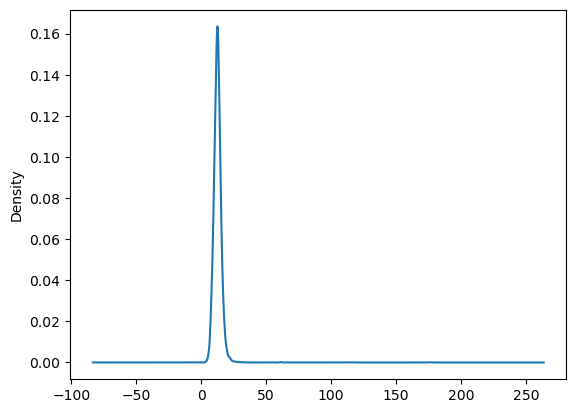

In [12]:
injected_df['content_flesch_kincaid_index'].plot(kind='kde')

In [13]:
print(injected_df['content_flesch_kincaid_index'].min())
print(injected_df['content_flesch_kincaid_index'].max())

3.3935872675250387
176.8958198071042


In [3]:
text = sampled_df.sample(n=1).content.iloc[0]

In [4]:
from readability import Readability

readability = Readability(text)

In [14]:
!conda remove py-readability-metrics

# packages in environment at /home/sakdag/miniconda3/envs/fake-news-classification:
#
# Name                    Version                   Build  Channel
py-readability-metrics    1.4.5              pyhd8ed1ab_0    conda-forge
